In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

SEED = 42  #创建变量
TARGET = "y"

raw = pd.read_csv("data/cs-training.csv")
print(raw.shape)     #raw.shape 返回一个元组（tuple），表示行数，列数
raw.head()

(150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
#表unnamed：ID、流水号、行号这类字段三条都不满足，不能解释任何风险内涵第一步就要删掉。
raw = raw.drop(columns=["Unnamed: 0"])

rename_map = {            #一个"旧名 → 新名"的对照表。原列名太长，后面写代码会很痛苦
    "SeriousDlqin2yrs": "y",  #未来两年是否发生严重逾期；目标变量，需要预测的结果
    "RevolvingUtilizationOfUnsecuredLines": "util",#无抵押循环信用额度使用率；观察客户信用额度使用情况
    "age": "age",
    "NumberOfTime30-59DaysPastDueNotWorse": "dpd30",#发生30—59天逾期的次数	历史逾期特征
    "DebtRatio": "debt_ratio",#债务负担比率	衡量客户债务负担，需注意数据集的具体定义
    "MonthlyIncome": "income",#月收入	衡量客户收入能力
    "NumberOfOpenCreditLinesAndLoans": "open_lines",#未结清信贷账户与贷款数量	反映账户和贷款数量
    "NumberOfTimes90DaysLate": "dpd90",#发生90天及以上逾期的次数	历史严重逾期特征
    "NumberRealEstateLoansOrLines": "re_loans",#房地产相关贷款或信贷额度数量	反映房贷及房地产信贷情况
    "NumberOfTime60-89DaysPastDueNotWorse": "dpd60",#发生60—89天逾期的次数	历史中度逾期特征
    "NumberOfDependents": "dependents",#被抚养人数	反映家庭负担相关信息
}
df = raw.rename(columns=rename_map)

print(df.shape)
print("坏账率：{:.2%}".format(df[TARGET].mean()))  #取y列，求平均值；显示格式：两位小数百分比格式；然后format() 返回的是字符串，而不是用于后续计算的数值。
df.head()

(150000, 11)
坏账率：6.68%


,y,util,age,dpd30,debt_ratio,income,open_lines,dpd90,re_loans,dpd60,dependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
#为什么要先看坏账率：费信贷的坏账率一般在几个百分点到十几个百分点之间。如果算出来是 60%，或者 0.01%，很可能是标签定义错了，或者取数出了问题。这是一道合理性检查。
#它是后面所有判断的基准：后面每看一个分箱的坏账率，比如"年轻人坏账率 11%"，都要和整体的 6.68% 比较，才知道它是高还是低。
#进入第 2 步：探索性分析（EDA），EDA 的目的就是像体检一样把每个变量查一遍：有没有缺失？有没有离谱的值？
eda = pd.DataFrame({
    "缺失率": df.isna().mean(),
    "最小值": df.min(),
    "1%分位": df.quantile(0.01),#1% 分位数：从小到大排，排在第 1% 位置的值
    "中位数": df.median(),
    "99%分位": df.quantile(0.99),
    "最大值": df.max(),
}).round(3)
eda


,缺失率,最小值,1%分位,中位数,99%分位,最大值
y,0.000,0.0,0.0,0.000,1.000,1.0
util,0.000,0.0,0.0,0.154,1.093,50708.0
age,0.000,0.0,24.0,52.000,87.000,109.0
dpd30,0.000,0.0,0.0,0.000,4.000,98.0
debt_ratio,0.000,0.0,0.0,0.367,4979.040,329664.0
income,0.198,0.0,0.0,5400.000,25000.000,3008750.0
open_lines,0.000,0.0,0.0,8.000,24.000,58.0
dpd90,0.000,0.0,0.0,0.000,3.000,98.0
re_loans,0.000,0.0,0.0,1.000,4.000,54.0
dpd60,0.000,0.0,0.0,0.000,2.000,98.0


In [4]:
#总结该表问题：
#1.income 缺 20%，dependents 缺 2.6%	客户没填
#2.年龄有 0 岁	录入错误
#3.逾期次数有 98	系统特殊编码
#4.util 最大 5 万	脏数据
#5.debt_ratio 顶端大量离谱值	这批人这列存的可能不是"比率"
#动手验证问题 3 和问题 5
# 验证问题 3：98 是不是特殊编码
print("dpd30 取值最大的几种：")#value_counts()：统计这一列中，每个不同的数值出现了多少次，且索引变成了 dpd30 的不同取值。
print(df["dpd30"].value_counts().sort_index().tail(6))#sort_index() 不是按照Series里面的频数排序，而是按照它的索引标签排序。最后6行就是dpd30最大的6种不同取值，以及每一种出现了多少次。

special = df["dpd30"].isin([96, 98])#检查每个值是否属于列表 [96, 98]。返回的是一列TF series
print("\n这批人的三个逾期字段：")
print(df.loc[special, ["dpd30", "dpd60", "dpd90"]].drop_duplicates())#取出行为T，列为那三个（即观察的字段）的表格，然后剔除重复数据，我们看的是：有多少种不同的逾期字段组合。
print("这批人的坏账率：{:.1%}".format(df.loc[special, TARGET].mean())) #只取这批人，求坏账率

# 验证问题 5：debt_ratio 和收入缺失有没有关系
print("\n收入缺失 vs 不缺失时，debt_ratio 的中位数：")
print(df.groupby(df["income"].isna())["debt_ratio"].median())#先取收入列，判断TF，按TF分组，分完组后，只选出 debt_ratio 这一个字段，最后分别计算两组客户的 debt_ratio 中位数。

dpd30 取值最大的几种：
dpd30
10      4
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64

这批人的三个逾期字段：
       dpd30  dpd60  dpd90
1733      98     98     98
41944     96     96     96
这批人的坏账率：54.6%

收入缺失 vs 不缺失时，debt_ratio 的中位数：
income
False       0.296023
True     1159.000000
Name: debt_ratio, dtype: float64


In [5]:
#这批人的坏账率：这说明他们虽然数据是乱码，却是风险极高的一群人。
def bad_rate_by_quantile(data, col, q=10):#（数据表，指标名称，多少组）
    s = data[[col, TARGET]].dropna()#只取两列
    bins = pd.qcut(s[col], q=q, duplicates="drop")#取col列，qcut等频分箱（每组个数一样，而非长度一样），删掉重复值以免分割点重复。bins生成一系列区间
    return s.groupby(bins, observed=True)[TARGET].agg(["count", "mean"]).rename(columns={"mean": "坏账率"})
#按bins分组，只保留观察到的数据；然后只取y，同时计算数量和平均值（坏账率），将输出结果中原来的mean列名改成中文的坏账率。最终结构：年龄区间-count-坏账率
for col in ["age", "util", "income"]:#针对年龄、收入、信用额度使用率分别写三遍代码
    print(f"\n==== {col} ====")
    print(bad_rate_by_quantile(df, col).round(4))


==== age ====
                count     坏账率
age                          
(-0.001, 33.0]  17085  0.1135
(33.0, 39.0]    14919  0.0959
(39.0, 44.0]    15799  0.0864
(44.0, 48.0]    14741  0.0814
(48.0, 52.0]    14826  0.0770
(52.0, 56.0]    14214  0.0658
(56.0, 61.0]    16878  0.0497
(61.0, 65.0]    12939  0.0375
(65.0, 72.0]    14258  0.0267
(72.0, 109.0]   14341  0.0216

==== util ====
                   count     坏账率
util                            
(-0.001, 0.00297]  15000  0.0252
(0.00297, 0.0192]  15000  0.0136
(0.0192, 0.0435]   15000  0.0140
(0.0435, 0.0832]   15000  0.0191
(0.0832, 0.154]    15000  0.0237
(0.154, 0.271]     15000  0.0347
(0.271, 0.445]     15000  0.0525
(0.445, 0.699]     15000  0.0880
(0.699, 0.981]     15000  0.1659
(0.981, 50708.0]   15000  0.2317

==== income ====
                      count     坏账率
income                             
(-0.001, 2005.0]      12028  0.0844
(2005.0, 3000.0]      13056  0.0967
(3000.0, 3800.0]      11322  0.0911
(3800.0, 4544.2

In [6]:
#小结
#变量	方向	区分能力	特点
#age	越大越安全	中	完全单调
#util	越大越危险	强（2%→23%）	开头有小反弹
#income	越高越安全	弱（9%→4.5%）	开头有小反弹
#对 debt_ratio 和 open_lines 跑同样的函数。
for col in ["debt_ratio", "open_lines"]:
    print(f"\n==== {col} ====")
    print(bad_rate_by_quantile(df, col).round(4))


==== debt_ratio ====
                    count     坏账率
debt_ratio                       
(-0.001, 0.0309]    15000  0.0538
(0.0309, 0.134]     15000  0.0682
(0.134, 0.214]      15000  0.0603
(0.214, 0.287]      15000  0.0541
(0.287, 0.367]      15000  0.0561
(0.367, 0.468]      15000  0.0674
(0.468, 0.649]      15001  0.0841
(0.649, 4.0]        15108  0.1133
(4.0, 1267.0]       14896  0.0608
(1267.0, 329664.0]  14995  0.0498

==== open_lines ====
               count     坏账率
open_lines                  
(-0.001, 3.0]  22050  0.1070
(3.0, 4.0]     11609  0.0640
(4.0, 5.0]     12931  0.0633
(5.0, 6.0]     13614  0.0554
(6.0, 8.0]     25807  0.0524
(8.0, 9.0]     11355  0.0585
(9.0, 10.0]     9624  0.0596
(10.0, 12.0]   15326  0.0596
(12.0, 15.0]   13858  0.0643
(15.0, 58.0]   13826  0.0691


In [7]:
##数据清洗
def clean(data):
    d = data.copy() #copy() 的核心作用是避免直接修改原始数据。

    # 问题 3：逾期字段的 96/98
    dpd_cols = ["dpd30", "dpd60", "dpd90"]
    d["dpd_special"] = d["dpd30"].isin([96, 98]).astype(int)#isin() 的作用是判断某个值是否属于指定集合。然后将布尔值转化为整数；所以它是我们自己创建的一个新变量，用来标记客户原来的 dpd30 是否出现过96或98。
    for c in dpd_cols:
        d.loc[d[c].isin([96, 98]), c] = np.nan#d.loc[]：按照指定条件定位数据。条件：找出等于96或98的记录。c：指定要修改的列。np.nan：将对应数据改成缺失值。

    # 问题 2：年龄为 0
    d.loc[d["age"] <= 0, "age"] = np.nan

    # 问题 4：util 极端值，截断在 1.1
    d["util"] = d["util"].clip(upper=1.1)#clip() 的意思是截断。所有大于1.1的数字都被替换成1.1。这种方法在数据处理中也叫 Winsorization（缩尾处理）。

    # 问题 5：收入缺失时 debt_ratio 含义不同
    d["income_missing"] = d["income"].isna().astype(int)  #标记0/1代表是否缺失
    d.loc[d["income_missing"] == 1, "debt_ratio"] = np.nan#等于1的把debt_ratio写成缺失。如果收入缺失，就将债务比率也设置为缺失值。
    d["debt_ratio"] = d["debt_ratio"].clip(upper=5)#将债务比率的最大值限制在5。

    return d

df_clean = clean(df)  #把原来的 df 传入函数，清洗完成后，将结果保存为 df_clean。
df_clean.describe().T[["count", "min", "50%", "max"]].round(3)#每次清洗完，都要用 describe() 检查一遍，确认改动生效、没有误伤。面试时说"我清洗后会核对记录数和取值范围"，面试官会觉得你做事严谨。

,count,min,50%,max
y,150000.0,0.0,0.000,1.0
util,150000.0,0.0,0.154,1.1
age,149999.0,21.0,52.000,109.0
dpd30,149731.0,0.0,0.000,13.0
debt_ratio,120269.0,0.0,0.296,5.0
income,120269.0,0.0,5400.000,3008750.0
open_lines,150000.0,0.0,8.000,58.0
dpd90,149731.0,0.0,0.000,17.0
re_loans,150000.0,0.0,1.000,54.0
dpd60,149731.0,0.0,0.000,11.0


In [8]:
#负债比几千、几十万的人，坏账率反而只有 5%？不合常理。
#原因就是昨天发现的问题 5：最后两段的人，大部分是收入缺失的人，他们这一列存的是还款金额（上千元），不是比率。他们根本不是"负债很重的人"，只是数据存法不同。
#open_lines：真正的 U 型——
#笔数太少（≤3）：可能是信用记录很薄的人，比如刚工作、刚办卡；也可能是在别的机构申请被拒了，所以手上没几张卡。机构对这类人了解少，风险就高。风控里叫"白户"或"薄信用记录"。
#笔数太多（15+）：同时在很多地方借钱，叫多头借贷。这往往说明这个人资金很紧张，在"拆东墙补西墙"，风险会上升。
#下一步：跑清洗代码，验证 debt_ratio
print(bad_rate_by_quantile(df_clean, "debt_ratio").round(4))

                 count     坏账率
debt_ratio                    
(-0.001, 0.022]  12027  0.0493
(0.022, 0.108]   12027  0.0693
(0.108, 0.176]   12027  0.0629
(0.176, 0.237]   12027  0.0591
(0.237, 0.296]   12027  0.0530
(0.296, 0.36]    12026  0.0546
(0.36, 0.436]    12027  0.0672
(0.436, 0.543]   12027  0.0747
(0.543, 0.763]   12027  0.0968
(0.763, 5.0]     12027  0.1079


In [9]:
#第 4 步：特征衍生
#原始变量只有 10 个。实际工作中，风控建模大量时间都花在构造新变量上，因为好变量往往不是现成的，而是从业务理解中"算"出来的。
def add_features(data):
    d = data.copy()
    d["dpd_total"] = d[["dpd30", "dpd60", "dpd90"]].sum(axis=1, min_count=1)#总逾期次数；至少有一个非缺失值，才计算总和。
    d["dpd_any"] = (d["dpd_total"] > 0).astype(float)#是否发生过逾期。但是缺失值会变成false
    d.loc[d["dpd_total"].isna(), "dpd_any"] = np.nan#因此这一步把缺失值变成nan
    d["dpd_severity"] = d["dpd30"] + 2 * d["dpd60"] + 3 * d["dpd90"]#加权逾期严重程度
    d["monthly_debt"] = d["debt_ratio"] * d["income"]#估算月度债务支出
    d["income_per_person"] = d["income"] / (d["dependents"].fillna(0) + 1)#人均收入，fillna(0) 的意思是：把dependents中的缺失值填充为0。
    d["lines_per_age"] = d["open_lines"] / d["age"]#年龄对应的信贷账户数量
    d["re_share"] = d["re_loans"] / (d["open_lines"] + 1)#房地产贷款数量占比的近似指标，加一是为了避免0
    d["util_high"] = (d["util"] > 0.9).astype(int)#再新加一个变量：
    return d

df_feat = add_features(df_clean)
#将清洗后的数据表 df_clean 传入特征工程函数；
#在原有数据基础上增加7个新变量；
#将最终结果保存为 df_feat。
FEATURES = [c for c in df_feat.columns if c != TARGET]#让变量 c 依次代表数据表中的每一个列名。不要y，如果把y也放进X中，模型就相当于提前看到了答案，这叫目标泄漏（Target Leakage）
#等价：FEATURES = []
#for c in df_feat.columns:
  #  if c != TARGET:
    #    FEATURES.append(c)
print(len(FEATURES), "个候选变量：")
print(FEATURES)
print(df_feat.groupby("util_high")[TARGET].agg(["count", "mean"]).round(4))#看看新加的变量的效果：这会显示：使用率超过 90%（1）和不超过（0）的两群人，各有多少人、坏账率是多少。

20 个候选变量：
['util', 'age', 'dpd30', 'debt_ratio', 'income', 'open_lines', 'dpd90', 're_loans', 'dpd60', 'dependents', 'dpd_special', 'income_missing', 'dpd_total', 'dpd_any', 'dpd_severity', 'monthly_debt', 'income_per_person', 'lines_per_age', 're_share', 'util_high']
            count    mean
util_high                
0          129931  0.0426
1           20069  0.2235


In [10]:
#第 5 步：划分训练集（分箱、训练模型，只用它学规律）、验证集（调参数、比较不同方案、给 LightGBM 早停）、测试集（最后只看一次，代表上线后的真实效果）
from sklearn.model_selection import train_test_split#导入随机划分数据集的函数

train, temp = train_test_split(df_feat, test_size=0.4, stratify=df_feat[TARGET], random_state=SEED)#按照y=0和y=1的比例进行分层抽样，使划分后的各个数据集尽可能保持原始的严重逾期率。
valid, test = train_test_split(temp, test_size=0.5, stratify=temp[TARGET], random_state=SEED)
#固定种子：让计算机每次以同一种可复现的方式随机选人。
for name, d in [("训练集", train), ("验证集", valid), ("测试集", test)]:
    print(f"{name}: {len(d):>6} 条，坏账率 {d[TARGET].mean():.2%}")#表示将数字在宽度为6的显示区域中右对齐。

训练集:  90000 条，坏账率 6.68%
验证集:  30000 条，坏账率 6.68%
测试集:  30000 条，坏账率 6.68%


In [11]:
##################################################################第 6 步：分箱、WOE 和 IV#######################################################################
#分箱：把连续变量切成几段，每段叫一个"箱"。目的：消除极端值影响，处理非线性关系，业务看得懂
#WOE：衡量"这一箱的人有多危险"：ln（坏占比/好占比）
#IV：衡量"整个变量的区分能力"，把每一箱的"占比差 × WOE"加起来。所以箱越多、每箱差别越大，IV 就越高。
#动手：用你的 util_high 手算一遍。util_high 天然只有两箱（0 和 1），最适合手算。正好验证一下我上次说的"IV 大约 0.6"。
t = train.groupby("util_high")[TARGET].agg(["count", "sum"])
t.columns = ["人数", "坏客户"]#给 DataFrame 的列名赋新值。
t["好客户"] = t["人数"] - t["坏客户"]
t["坏客户占比"] = t["坏客户"] / t["坏客户"].sum()
t["好客户占比"] = t["好客户"] / t["好客户"].sum()
t["WOE"] = np.log(t["坏客户占比"] / t["好客户占比"])
t["IV分项"] = (t["坏客户占比"] - t["好客户占比"]) * t["WOE"]

print(t.round(4))
print("\nIV =", round(t["IV分项"].sum(), 4))

              人数   坏客户    好客户  坏客户占比   好客户占比     WOE    IV分项
util_high                                                   
0          78008  3357  74651  0.558  0.8889 -0.4656  0.1540
1          11992  2659   9333  0.442  0.1111  1.3806  0.4568

IV = 0.6108


In [12]:
#自动分箱（上）：用决策树找切点。
#util_high 的切点 0.9 是我们手动定的。但变量很多，每个都手动定不现实。标准做法是让决策树帮你找：决策树会自动寻找"切在哪里，能让两边的坏账率差别最大"。
#对比
#	           qcut 等频分箱	        决策树分箱
#是否用到 y	    不用（无监督）	   用（有监督）
#切点由什么决定	人数的分位数	     坏账率的差异
#箱数	     固定（我们用了 10）	自动，最多 6
#每箱人数	   大致相等	           不等，但每箱至少 5%
#用在哪里	EDA：快速看趋势	    建模：正式定箱
from sklearn.tree import DecisionTreeClassifier

def tree_cut_points(x, y, max_bins=6, min_leaf=0.05):  #（要分的东西，监督的东西，最多分成几个区间，每个叶节点至少包含约5%的有效训练样本）
    mask = x.notna()  #非缺失值为T
    tree = DecisionTreeClassifier(
        max_leaf_nodes=max_bins,#最多产生6个有效分箱，通常最多对应5个不同的切点。
        min_samples_leaf=max(int(mask.sum() * min_leaf), 1),#每一个叶节点至少要包含多少条有效客户记录。限制每箱最小样本量，避免决策树切出过小的组，并保证至少为1
        random_state=SEED,
    )
    tree.fit(x[mask].to_frame(), y[mask]) #怎样根据util的大小切分客户，使不同组的违约标签分布产生较明显的差异。
    th = tree.tree_.threshold[tree.tree_.feature >= 0]#tree.tree_可以访问它内部已经学好的树结构。threshold这个属性存储所有树节点对应的阈值。feature >= 0 是为了排除叶子节点，叶子没有切点
    return sorted(set(th))#th 是一个 NumPy ndarray（一维数组），里面保存决策树找到的切点。set把数组转成集合，去除重复的切点。从小到大排

#至此，第一个函数就完成了：输入x和y，输出一组按照风险标签学习出来的分箱切点。
#下一步：根据这些切点，把客户真正分箱，并计算每一箱的好坏客户数量、坏账率、WOE和IV。
def woe_table(x, y, cuts):
    eps = 0.5#后面计算时，对每组的好客户数和坏客户数都加上0.5，起到一定的平滑作用，以免出现ln0
    total_bad, total_good = y.sum(), (1 - y).sum()
    edges = [-np.inf] + list(cuts) + [np.inf]  #三个区间，包含正负无穷
    bins = pd.cut(x, bins=edges)#pd.cut() 就会按照这些边界，把每一个客户的util分配到对应区间。
    labels = bins.astype(str).where(x.notna(), "Missing")#将分箱区间转换为字符串。where(条件, 替换值) 的含义是：条件为T保留原值，F则替换成指定值

    g = pd.DataFrame({"bin": labels, "y": y}).groupby("bin")["y"].agg(["count", "sum"])#字典→dataframe；再按bins分组，只关注y，算count和sum
    g.columns = ["n", "bad"]#改列名（总人数，坏人数）
    #按照原本分箱区间的数值顺序，依次取出每个存在的分箱名称，保存成一个列表。
    order = [str(c) for c in bins.cat.categories if str(c) in g.index]#让c依次等于区间，str把区间转化为字符串，检查这个区间是否真的出现在 g 的行索引中，有的区间可能没有用户
    if "Missing" in g.index: #如果g中有缺失，放到上述列表的最后
        order.append("Missing")
    g = g.loc[order]#按照这个列表的顺序重新排列 g 的行。

    g["good"] = g["n"] - g["bad"]
    g["bad_rate"] = g["bad"] / g["n"]
    g["woe"] = np.log(((g["bad"] + eps) / total_bad) / ((g["good"] + eps) / total_good))
    g["iv_i"] = (g["bad"] / total_bad - g["good"] / total_good) * g["woe"]
    return g


cuts = tree_cut_points(train["util"], train[TARGET])#这里x，y分别传入，生成cuts切点，为list
print("切点：", [round(c, 3) for c in cuts]) #对于cuts里的切点保留三位小数生成列表
tab = woe_table(train["util"], train[TARGET], cuts) #传入x，y，cuts
print(tab[["n", "bad", "bad_rate", "woe"]].round(4)) #打印要显示的列
print("IV =", round(tab["iv_i"].sum(), 4))

切点： [np.float64(0.132), np.float64(0.301), np.float64(0.501), np.float64(0.699), np.float64(0.941)]
                    n   bad  bad_rate     woe
bin                                          
(-inf, 0.132]   42644   799    0.0187 -1.3215
(0.132, 0.301]  13059   437    0.0335 -0.7260
(0.301, 0.501]   9523   554    0.0582 -0.1473
(0.501, 0.699]   6786   665    0.0980  0.4172
(0.699, 0.941]   7389  1143    0.1547  0.9383
(0.941, inf]    10599  2418    0.2281  1.4175
IV = 1.0973


In [13]:
#自动分箱（下）：强制单调
#util 天然单调，很省心。但不是每个变量都这样，比如 EDA 里看到的 open_lines 是 U 型。
#为什么评分卡通常要求单调？业务上说得通：评分卡会被审批人员、监管看到。"额度用得越多扣分越多"大家都能接受。更稳定：不单调的小起伏，很多是样本里的随机波动，换一批客户就消失了。
#**怎么强制单调？**很简单：找到"方向不一致"的相邻两箱，把它们合并，然后重新检查，直到坏账率一路上升或一路下降为止。
def bin_stats(x, y, cuts):  #传入x，y，列表切点，
    edges = [-np.inf] + list(cuts) + [np.inf] #拓展列表至无穷
    b = pd.cut(x, bins=edges)#b 是一个Categorical类型的Series，它的长度仍然和 x 一样，每个客户对应一个分箱标签。
    g = pd.DataFrame({"bin": b, "y": y}).groupby("bin", observed=False)["y"].agg(["count", "sum"])#observed=False 表示保留所有定义好的分类区间，包括可能没有客户的空箱。
    g.columns = ["n", "bad"] #改列名
    g["bad_rate"] = g["bad"] / g["n"].replace(0, np.nan)#先将人数n为0的分母替换成NaN。注意并没有改变原n的0
    return g



def make_monotonic(x, y, cuts):
    cuts = list(cuts)#重新创建复制列表切点
    while len(cuts) > 1:#切点个数大于1就执行
        br = bin_stats(x, y, cuts)["bad_rate"].values#先得到dataframe，取坏账率series，取数值，得到坏账率数组
        diff = np.diff(br)#np.diff() 计算相邻两个元素之间的差值
        if np.all(diff > 0) or np.all(diff < 0):#检查是否单调（全部大于0或全部小于0）
            break#break 的意思是结束当前循环，而不是结束整个Python程序。
        trend = np.sign(br[-1] - br[0]) or 1.0#最后一个值-第一个值的符号，正数（1），负数（-1），0（→1）#用于判断整体趋势方向
        bad_idx = np.where(np.sign(diff) != trend)[0]##np.where()：找出违反趋势的位置，结果为：举例(array([1, 3]),)，然后取出这个元组里的第一个元素，1；也可以理解为：np.where 返回的格式外面多包了一层，[0] 是把它剥掉，只取出这个位置数

#表达式	结果	类型
#np.where(条件)	(array([1]),)	tuple
#np.where(条件)[0]	array([1])	ndarray
#bad_idx	array([1])	ndarray
#bad_idx[0]	1	NumPy整数（通常是np.int64）
        
        cuts.pop(bad_idx[0])#从列表中删除索引位置为1的元素,删除相邻两箱之间的边界。
    return cuts #返回单调处理后的切点


x, y = train["open_lines"], train[TARGET]
cuts_raw = tree_cut_points(x, y)  #根据x和y自动寻找切点
cuts_mono = make_monotonic(x, y, cuts_raw)#执行单调处理后的切点

print("强制单调前，切点：", [round(float(c), 1) for c in cuts_raw])
print(woe_table(x, y, cuts_raw)[["n", "bad_rate", "woe"]].round(4))
print("\n强制单调后，切点：", [round(float(c), 1) for c in cuts_mono])#代价：丢掉的是"多头借贷"的风险。
print(woe_table(x, y, cuts_mono)[["n", "bad_rate", "woe"]].round(4))

强制单调前，切点： [2.5, 3.5, 5.5, 8.5, 13.5]
                 n  bad_rate     woe
bin                                 
(-inf, 2.5]   7741    0.1292  0.7284
(2.5, 3.5]    5417    0.0753  0.1296
(3.5, 5.5]   14675    0.0636 -0.0520
(5.5, 8.5]   23657    0.0533 -0.2396
(8.5, 13.5]  25130    0.0588 -0.1362
(13.5, inf]  13380    0.0698  0.0470

强制单调后，切点： [2.5, 3.5, 5.5]
                 n  bad_rate     woe
bin                                 
(-inf, 2.5]   7741    0.1292  0.7284
(2.5, 3.5]    5417    0.0753  0.1296
(3.5, 5.5]   14675    0.0636 -0.0520
(5.5, inf]   62167    0.0591 -0.1313


In [14]:
#表格解读：排在前面的**共同点：都在描述一个人"过去怎么还钱"。**风控里有句老话：**过去的还款行为，是预测未来还款最好的依据。**以前逾期过的人，以后更可能逾期。
#前三名全是衍生变量，都排在原始的 dpd90、dpd30 前面。尤其 dpd_severity（按严重程度加权），IV 1.40 是全场最高。这说明特征衍生真的有用。
#如果 dpd90 统计的逾期次数里，包含了申请之后、表现期内发生的逾期，那它就直接包含了答案：只要 y = 1，dpd90 至少是 1。这就是最典型的泄露。
#那到底泄露了没有？用数据检验
print(pd.crosstab(train["dpd90"] > 0, train[TARGET], margins=True))

y          0     1    All
dpd90                    
False  81108  3993  85101
True    2876  2023   4899
All    83984  6016  90000


In [15]:
#对所有变量批量分箱，算出 IV 排名
def fit_binning(data, features, monotonic=True):
    result = {}
    for col in features:#之前的features里面有19个变量
        x, y = data[col], data[TARGET]
        cuts = tree_cut_points(x, y)
        if monotonic:
            cuts = make_monotonic(x[x.notna()], y[x.notna()], cuts)#就是筛选出x非缺失的客户。把这些客户对应的y标签也筛选出来。
        result[col] = {"cuts": cuts, "table": woe_table(x, y, cuts)}#result这个大字典里，每个特征又对应一个小字典。小字典装着该特征的切点和分箱统计结果
    return result


bins = fit_binning(train, FEATURES)


iv = pd.Series({c: bins[c]["table"]["iv_i"].sum() for c in FEATURES}).sort_values(ascending=False)#列表推导式，键为c，值为bins[c]["table"]["iv_i"].sum()即IV值；最后得到一个按IV从高到低排列的Series，索引是变量名称，数值是IV。
iv_df = iv.round(4).to_frame("IV")#to_frame() 可以把Series转换成DataFrame。额外指定了新DataFrame的列名叫 "IV"。
iv_df["区分能力"] = pd.cut(iv, [-1, 0.02, 0.1, 0.3, 0.5, 99], labels=["无用", "弱", "中", "强", "极强"])#根据iv，分到人为制定的箱子里，6个边界数字，形成5个区间，因此需要5个标签。
iv_df

,IV,区分能力
dpd_severity,1.4010,极强
dpd_total,1.3514,极强
dpd_any,1.1737,极强
util,1.0973,极强
dpd90,0.8502,极强
dpd30,0.7147,极强
util_high,0.6108,极强
age,0.2285,中
income_per_person,0.1018,中
income,0.0804,弱


In [16]:
#坏客户一共 6016 人，其中 dpd90 > 0 的只有 2023 人，占 33.6%。也就是说，三分之二的坏客户，申请时从来没有过 90 天以上逾期。
#如果 dpd90 包含了表现期内的逾期，那么每个坏客户都至少逾期过一次 90 天（标签就是这么定义的），这个比例应该接近 100%。实际只有三分之一，不符合泄露的特征。

#第 7 步：变量筛选（第 1 道筛子）
#现在有 20 个候选变量，但不能全部放进模型。原因是：
#   有些变量几乎没用，比如 IV 接近 0 的。
#   有些变量互相重复，比如 dpd_total 和 dpd_severity 描述的几乎是同一件事。放太多重复变量，逻辑回归的系数会变得不稳定，甚至方向反了。
#所以要过5 道筛子，层层剔除：

#顺序	    筛子	                 剔除什么
#1	         IV	                 区分能力太弱的
#2	       相关性	         和别的变量高度重复的
#3	     LightGBM 重要性	    在多变量一起时贡献很小的
#4	        VIF	            多重共线性严重的
#5	      系数符号	      逻辑回归里方向不对的
#先把所有变量转成 WOE：后面的相关性、VIF、逻辑回归，用的都不是原始数值，而是 WOE 值。
def to_woe(data, bins, features):#bins是前面fit_binning得到的嵌套字典，大致长这样：bins = {
    #                                                                                  "util": {
   #                                                                                       "cuts": [0.3, 0.7],
   #                                                                                      "table": util的WOE统计表
   #                                                                                    },
    #                                                                                  "age": {
      #                                                                                    "cuts": [30.5, 45.5],
      #                                                                                    "table": age的WOE统计表
  #                                                                                     }
    #                                                                                       其余变量……
#}
    out = pd.DataFrame(index=data.index)#创建空dataframe，保持原索引
    for col in features:
        cuts = bins[col]["cuts"]#cuts是列表，table是DataFrame
        table = bins[col]["table"]
        edges = [-np.inf] + list(cuts) + [np.inf]
        labels = pd.cut(data[col], bins=edges).astype(str)#利用之前确定的切点给每个客户分箱。结果仍然是Series，但值属于分类区间类型。把区间转成字符串
        labels = labels.where(data[col].notna(), "Missing")#
        mapping = table["woe"].to_dict()#它从WOE统计表中取出woe这一列。把Series转换成字典。得到mapping={区间：woe值}
        out[col] = labels.map(mapping).fillna(0.0)#就是逐个读取lables Series中的分箱名称，然后去字典中查找对应的WOE值。然后处理WOE映射结果中的缺失，而不是直接处理原始util的缺失。
    return out#现在我们已经得到当前变量的WOE编码Series。保存到out字典里，以该变量为列名。列名仍然叫util、age、income等，但这些列中保存的已经不是原始数值，而是WOE编码值

#从现在起，所有变量都用同一把尺子衡量：数值越大越危险。不管原来是年龄（岁）、收入（元）还是使用率（比例），全都变成了可以直接比较的风险值。
woe_train = to_woe(train, bins, FEATURES)
woe_valid = to_woe(valid, bins, FEATURES)
woe_test = to_woe(test, bins, FEATURES)
y_train, y_valid, y_test = train[TARGET], valid[TARGET], test[TARGET]

print(train[["util", "age"]].head(3))
print(woe_train[["util", "age"]].head(3))

            util   age
15901   1.000000  67.0
149886  0.463773  51.0
54863   0.034308  55.0
            util       age
15901   1.417476 -0.954945
149886 -0.147315  0.178661
54863  -1.321549  0.006294


In [17]:
#第 1 道筛子：IV 筛选
step1 = iv[iv >= 0.02].index.tolist()#仅保留条件为True的元素。把Index转换为list。
print(f"IV 筛选：{len(FEATURES)} → {len(step1)}")
print("剔除：", sorted(set(FEATURES) - set(step1)))#集合差集；对于字符串，默认按照字典序排序。

IV 筛选：20 → 16
剔除： ['dpd_special', 'income_missing', 're_loans', 're_share']


In [18]:
#第 2 道筛子：相关性筛选
#问题：剩下的 16 个变量里，有不少在说同一件事。比如 dpd_total、dpd_any、dpd_severity 都在描述"过去逾期得多不多"。
#规则：
#把变量按 IV 从高到低排队。
#从第一个开始，依次决定要不要保留。
#如果它和已经保留的任何一个变量的相关系数超过 0.7，就剔除；否则保留。
corr = woe_train[step1].corr().abs()#计算所有保留特征两两之间的相关性。行索引：特征名称。列名：特征名称。数值是WOE特征之间的相关系数绝对值
step2 = []
for col in iv[step1].sort_values(ascending=False).index:#按照列表中的变量名称，从Series中选出对应的IV。从高到低排，只取index名称
    #对于当前变量col，检查它和所有已经保留的变量之间的相关系数绝对值。如果全部不超过0.7，就把col加入保留列表step2。
    if all(corr.loc[col, kept] <= 0.7 for kept in step2):#对于该col，对所有kept取相关值，找到表中的系数值，判断0.7，与所有kept都小与0.7就加入step2
        step2.append(col)

print(f"相关性筛选：{len(step1)} → {len(step2)}")
print("剔除：", sorted(set(step1) - set(step2)))
print("保留：", step2)

相关性筛选：16 → 11
剔除： ['dpd30', 'dpd_any', 'dpd_total', 'lines_per_age', 'util_high']
保留： ['dpd_severity', 'util', 'dpd90', 'age', 'income_per_person', 'income', 'open_lines', 'debt_ratio', 'dpd60', 'dependents', 'monthly_debt']


In [19]:
#**规律：剔除的大多是"从某个变量派生出来"的，或者"它是别人的一部分"。**每一组里留下的，都是 IV 最高的那个。
#一个值得想一想的地方：dpd90 和 dpd60 也是逾期变量，而且 dpd_severity 里也包含它们，为什么没被剔除？
#因为相关性看的是两个变量的取值是否一起变化。绝大多数人逾期 30 天的次数多，dpd_severity 主要由 dpd30 驱动，所以两者高度相关。而有过 90 天、60 天逾期的人只占很小一部分，大多数人在这两个变量上都是 0，和 dpd_severity 的变化不完全同步，相关系数就没超过 0.7。
print(corr.loc[["dpd_total", "dpd_any", "dpd30", "dpd90", "dpd60"], "dpd_severity"].round(3))

dpd_total    0.957
dpd_any      0.933
dpd30        0.767
dpd90        0.688
dpd60        0.146
Name: dpd_severity, dtype: float64


In [20]:
#第 3 道筛子：LightGBM 重要性
#LightGBM 是一种树模型，它会把所有变量一起考虑，然后告诉你：在其他变量都在的情况下，每个变量额外贡献了多少。
import lightgbm as lgb

lgb_screen = lgb.LGBMClassifier(            #规定模型应该如何训练。每棵树最多叶节点15（15组）；每个叶节点最低样本量200
    n_estimators=2000, learning_rate=0.03, num_leaves=15, min_child_samples=200,#最多训练2000轮，学习率0.03，学习率 = 模型每次“认错改错”时，改的幅度有多大。
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,#subsample=0.8：每次启用行采样时，抽取大约80%的训练样本（抽行）参与该轮树训练。subsample_freq=1：每轮进行一次这种采样。
    random_state=SEED, verbose=-1,#抽列0.8，避免依赖同一批变量。        不希望树的某些叶节点做出过于极端的预测调整。不允许预测幅度太大
)#固定种子。LightGBM 是个训练工具，它工作时喜欢在屏幕上“自言自语”打报告。verbose 就是管它嘴巴的。


#===============================================================================================================================
#结合 LightGBM 的核心概念总结一下：
#LightGBM 为什么厉害？因为它是极其聪明的“审核团队”。

#“每棵树最多 15 个叶节点”：你告诉每一个审核员：“你最多只能下 15 种不同的结论，别给我搞太复杂的分类，抓大放小！”

#“最多训练 2000 轮”：你安排了 2000 个审核员排队上场，后一个专门修前一个的错。

#“不同树和分支中灵活切分”：这 2000 个审核员，每个人问问题的角度不一样。1号喜欢问收入，2号喜欢问年龄，3号喜欢问工作年限……

#最后，这 2000 个只做简单判断的审核员，组合在一起，就变成了一个极其强大的预测系统（这就是所谓的集成学习）。

#================================================================================================================================


#fit()真正开始训练模型
lgb_screen.fit(
    train[step2], y_train,#让LightGBM学习，如何根据这些客户特征预测y=0或y=1
    eval_set=[(valid[step2], y_valid)], eval_metric="auc",#验证集的x，y。然后希望评估模型的AUC，AUC衡量模型把坏客户排在好客户前面的能力，auc=1就是完美排序。另外，eval_metric用于验证评估，不等于模型训练时直接最大化AUC。
    callbacks=[lgb.early_stopping(100, verbose=False)],#如果验证指标连续100轮都没有达到新的最佳表现，就提前停止训练。
)
#完成训练后，lgb_screen是训练完成的模型对象，里面保存了训练得到的树、特征信息、验证结果等。
imp = pd.Series(lgb_screen.booster_.feature_importance("gain"), index=step2)#回各特征的重要性。一个变量的Gain重要性，就是它参与模型分裂时产生的Gain累计值。返回一个NumPy数组。然后设置index，并返回series
imp = (imp / imp.sum()).sort_values(ascending=False)#将gain转化为占比
print("最优迭代轮数：", lgb_screen.best_iteration_)
imp.round(4).to_frame("gain 占比")

最优迭代轮数： 331


,gain 占比
dpd_severity,0.5510
util,0.2123
dpd90,0.0578
debt_ratio,0.0337
age,0.0324
monthly_debt,0.0280
open_lines,0.0252
income,0.0230
income_per_person,0.0183
dpd60,0.0154


In [21]:
#debt_ratio 和 monthly_debt 的 IV 很低，在树模型里却挺重要。原因有两个：
#交互作用：树模型能发现"年轻且负债比高"这种组合效应，单变量的 IV 看不出来。
#非线性：树可以在任意位置切很多刀，而 IV 受限于最多 6 箱、强制单调。

#按 gain 筛选，然后做第 4 道筛子：VIF
#第 3 道筛子的规则：gain 占比 < 0.5% 的剔除
step3 = imp[imp >= 0.005].index.tolist() #因为我们最终想要的是变量名称列表
print(f"LightGBM 重要性筛选：{len(step2)} → {len(step3)}")
print("剔除：", sorted(set(step2) - set(step3)))

LightGBM 重要性筛选：11 → 10
剔除： ['dependents']


In [22]:
#第 4 道筛子：VIF（方差膨胀因子）
#相关性筛选的漏洞：它只检查两两之间是否重复。但有可能 A 和 B、A 和 C 单独看都不太相关，B 和 C 加在一起却能把 A 几乎完全算出来。这叫多重共线性，两两相关系数发现不了。
#VIF 的做法：对每个变量，用其他所有变量去回归它，看能解释多少。VIF越大，说明当前特征与其他特征存在越严重的线性冗余。
def calc_vif(X):
    vals = {}
    for col in X.columns:
        #把当前变量以外的所有变量取出来，并在最前面添加一列全为1的数字，构成用于线性回归的X矩阵：
        others = np.c_[np.ones(len(X)), X.drop(columns=col).values]#.values 就是把Pandas DataFrame中的数值取出来，转换为NumPy数组。np.ones(len(X))生成一维np数组。np.c_[]：把数组按列拼接。
    #此时others	二维ndarray	用于预测age的其他变量及截距列；X[col].values	一维ndarray	真正的age数值。
    #np.linalg.lstsq最小二乘法。
    #把第一个返回结果（即回归系数）赋给beta。把剩余三个结果收集进名为_的列表。后续不打算使用这些结果。
        beta, *_ = np.linalg.lstsq(others, X[col].values, rcond=None)
    #计算残差
        resid = X[col].values - others @ beta  #@是Python中的矩阵乘法运算符
    #计算R^2，RSS=(resid ** 2).sum()    TSS，代表当前特征本身的总体波动程度。
        r2 = 1 - (resid ** 2).sum() / ((X[col] - X[col].mean()) ** 2).sum()
    #把R²转换成VIF。每循环一次，就计算一个变量的VIF，并通过变量名称作为字典的键保存起来。
        vals[col] = 1 / (1 - r2)
    return pd.Series(vals).sort_values(ascending=False)#把字典转化为series，并将VIF从高到低排

calc_vif(woe_train[step3]).round(2).to_frame("VIF")#把Series转换成DataFrame，并把列名设置为VIF。


,VIF
income,2.07
income_per_person,2.03
dpd_severity,2.02
dpd90,1.98
debt_ratio,1.64
monthly_debt,1.50
util,1.32
open_lines,1.24
age,1.15
dpd60,1.05


In [23]:
#第 8 步：逻辑回归 + 第 5 道筛子（系数符号）
from sklearn.linear_model import LogisticRegression

def fit_lr(cols):#给它一个需要使用的变量列表，它就利用这些变量训练逻辑回归模型，最后返回训练好的模型。
    m = LogisticRegression(C=1.0, max_iter=1000)#C越小，正则化通常越强，；C越大，正则化通常越弱。允许优化算法最多进行1000次迭代
    m.fit(woe_train[cols], y_train)#就是让逻辑回归学习：这三个WOE变量与客户违约标签之间有什么统计关系。
    return m

final_vars = list(step3)#此处还要写一个list是为了创建一个新的列表，避免后面修改final_vars时影响step3。
while True:  #不断循环，除非程序内部主动执行break，或者出现异常。每次循环都会创建并训练一个新的模型，而不是继续在上一轮模型上追加训练。
    lr = fit_lr(final_vars) #循环重新执行lr计算系数
    coef = pd.Series(lr.coef_[0], index=final_vars)#这里coef_是sklearn训练后产生的属性。好像是名称-系数二维数组。取二维数组中的第一行。把系数数组转换成Series，并使用变量名称作为索引
    if (coef > 0).all():#：检查所有系数是否为正
        break
#coef在每一轮都会重新计算，因此删掉一个变量后，其他变量的系数也可能改变。
#每轮只删除当前系数最小的一个变量，不是一次删除全部负系数。
    drop = coef.idxmin()#返回的是最小值对应的索引标签
    print(f"剔除系数为负的变量：{drop}（系数 {coef[drop]:.3f}）")
    final_vars.remove(drop)

print(f"\n最终入模 {len(final_vars)} 个变量")
pd.DataFrame({"系数": coef.round(4), "IV": iv[final_vars].round(4)}).sort_values("IV", ascending=False)

剔除系数为负的变量：dpd60（系数 -0.109）
剔除系数为负的变量：open_lines（系数 -0.081）
剔除系数为负的变量：income_per_person（系数 -0.000）

最终入模 7 个变量


,系数,IV
dpd_severity,0.7056,1.4010
util,0.6147,1.0973
dpd90,0.1282,0.8502
age,0.3988,0.2285
income,0.2632,0.0804
debt_ratio,0.5594,0.0707
monthly_debt,0.6962,0.0344


In [24]:
#附：用 statsmodels 看 p 值
#银行的模型报告里，通常要列出每个变量的显著性。scikit-learn 不输出 p 值，要用 statsmodels，它的输出格式和你用过的 Stata 回归表很像。
import statsmodels.api as sm #statsmodels：Python统计建模库；api：提供常用统计模型接口的模块

sm_model = sm.Logit(y_train, sm.add_constant(woe_train[final_vars])).fit(disp=False)#sm.Logit(y, X)注意是先y后x。fit开始执行，用极大似然估计拟合系数。False表示不打印优化过程的信息。
#sm.add_constant()会给输入的DataFrame增加一列全为1的变量，列名叫const
#sm_model (BinaryResultsWrapper)：它是一个对象（Object）。对象是有“功能（方法）”的。
#你拥有了它，不仅拥有了数据，还拥有了随时提取这些数据、生成诊断报告的超能力。你不需要把它强转成表格，只需要用 . 去调用它肚子里的零件就行。

print(sm_model.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]].round(4))
#summary2()生成一个包含统计建模结果的摘要对象；取列表中索引为1的表格；，第二张表通常是回归系数统计表；选择系数、标准误、p值这三列；

               Coef.  Std.Err.  P>|z|
const        -2.6323    0.0166    0.0
dpd_severity  0.7051    0.0159    0.0
util          0.6171    0.0158    0.0
dpd90         0.1289    0.0183    0.0
debt_ratio    0.5578    0.0671    0.0
age           0.3927    0.0353    0.0
monthly_debt  0.7007    0.0977    0.0
income        0.2709    0.0591    0.0


In [25]:
#第 9 步：把模型变成评分卡
#逻辑回归输出的是违约概率，比如 0.0423。但业务人员和客户更习惯看分数，比如芝麻信用 650 分。
#PDO 刻度：怎么把概率换成分数
#先定两个"规矩"：

#                  设定	                                             含义
#     基准分 600，对应好坏比 20 : 1	          一个人如果每 21 人里只有 1 个坏人那么危险，就给他 600 分
#                PDO = 50	                   Points to Double the Odds：分数每加 50 分，好坏比翻一倍。650 分对应 40 : 1，700 分对应 80 : 1
#                                        只要你的分数加上 50 分（比如从 600 变成 650），你这个人的安全程度（好人比坏人）就翻了一倍（从 20:1 变成 40:1）。
BASE_SCORE, BASE_ODDS, PDO = 600, 20, 50 #基准分600，基准好坏比20，好坏比翻一倍（好人越多）加50分。  也就是说，1-p/p=20.即当模型预测违约概率p为约4.76%时，对应信用分为600分。
B = PDO / np.log(2)
A = BASE_SCORE - B * np.log(BASE_ODDS) #把概率转为分数：score=A-Bln（p/1-p）.已知比例翻倍+50分，即Blnx→Bln2x对应50，所以B=50/ln2。再代入基准600=A-Bln20

intercept = lr.intercept_[0]
#逻辑回归：ln(p/1-p)=β0+β1*WOE1+β2*WOE2+β3*WOE3...
#评分公式：score=A-Bln（p/1-p）
#所以score=A-B（β0+β1*WOE1+β2*WOE2+β3*WOE3...），即基础分=A-Bβ0，变量分为其他WOE
base_points = A - B * intercept#基础分
print(f"B = {B:.2f}，A = {A:.2f}")
print(f"基础分 = {base_points:.1f}")

rows = []
for col in final_vars:
    t = bins[col]["table"]#取出变量的完整WOE分箱统计表，得到dataframe
    beta = coef[col]#取出β值
    for b, r in t.iterrows():#逐行遍历DataFrame，得到索引（分箱）和行数据
        rows.append({"变量": col, "分箱": b, "样本数": int(r["n"]),  #每处理一个分箱，就创建一个字典，记录这个分箱对应的评分信息，再添加到rows列表中
                     "坏账率": round(r["bad_rate"], 4), "WOE": round(r["woe"], 4),
                     "分数": int(round(-B * beta * r["woe"]))})
scorecard = pd.DataFrame(rows) #每个变量的每个分箱一行，形成df
scorecard

B = 72.13，A = 383.90
基础分 = 573.7


,变量,分箱,样本数,坏账率,WOE,分数
0,dpd_severity,"(-inf, 0.5]",71740,0.0274,-0.9312,47
1,dpd_severity,"(0.5, 2.5]",10699,0.1140,0.5863,-30
2,dpd_severity,"(2.5, inf]",7401,0.3706,2.1067,-107
3,dpd_severity,Missing,160,0.5250,2.7357,-139
4,util,"(-inf, 0.132]",42644,0.0187,-1.3215,59
5,util,"(0.132, 0.301]",13059,0.0335,-0.7260,32
6,util,"(0.301, 0.501]",9523,0.0582,-0.1473,7
7,util,"(0.501, 0.699]",6786,0.0980,0.4172,-18
8,util,"(0.699, 0.941]",7389,0.1547,0.9383,-42
9,util,"(0.941, inf]",10599,0.2281,1.4175,-63


In [26]:
#观察missing箱发现：为什么是同一批人？都是收入缺失的人：
#income 缺失 → 自己落在 Missing 箱。
#清洗时规定：收入缺失的人，debt_ratio 也置为缺失 → 落在 Missing 箱。
#monthly_debt = debt_ratio × income，两个都缺，结果也缺失 → 落在 Missing 箱。

#给每个人打分
def score_frame(woe_df):
    pts = pd.DataFrame(index=woe_df.index)#原表index即客户号码，创建空白df
    for col in final_vars:
        pts[col] = -B * coef[col] * woe_df[col]#计算每个变量的得分
    return base_points + pts.sum(axis=1)#横向相加得到该客户得分

score_train = score_frame(woe_train)
score_valid = score_frame(woe_valid)
score_test = score_frame(woe_test)
print(score_test.describe().round(1))

count    30000.0
mean       627.7
std         88.1
min        319.8
25%        580.5
50%        652.3
75%        693.3
max        737.4
dtype: float64


In [27]:
#计算某个特定客户的分数
c = pd.DataFrame([{
    "util": 0.95, "age": 25, "dpd30": 1, "dpd60": 0, "dpd90": 0,
    "debt_ratio": 0.4, "income": 4000, "open_lines": 5,
    "re_loans": 0, "dependents": 0,
}])
c = add_features(clean(c))
print("代码算出的分数：", score_frame(to_woe(c, bins, final_vars)).round(1).iloc[0])

代码算出的分数： 465.0


In [28]:
#第 10 步：模型评估
#指标	                 含义	                                                           经验标准（A 卡）
#AUC	  随机抽一个坏客户和一个好客户，模型给坏客户打分更低的概率	                      0.7 以上可用，0.75–0.85 较好
#Gini	           = 2 × AUC − 1，                                                     就是 AUC 换了个刻度	
#KS	     好、坏客户累计分布的最大差距，衡量"最能把好坏分开的那个分数线"分得有多开	            0.3 以上可用，0.4–0.6 较好，超过 0.75 要怀疑过拟合或泄露
#PSI	            两批客户的分数分布是否稳定	                                          < 0.1 稳定，0.1–0.25 关注，> 0.25 不稳定
from sklearn.metrics import roc_auc_score, roc_curve#导入两个函数，直接计算AUC，计算绘制ROC曲线所需要的数据

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p) #roc_curve() 会返回三个结果：不同阈值下的假正率（错坏/全好），不同阈值下的真正率（正坏/全坏），对应的风险阈值。
    #风险阈值就是银行人为设定的一条分界线，用来决定客户被划分为好客户还是高风险客户。
    #阈值降低，识别的坏人更多但也可能误伤好人
    return float(np.max(tpr - fpr))#在所有可能的风险阈值中，模型最多能把坏客户和好客户区分开多大的距离

def evaluate(y, risk):
    auc = roc_auc_score(y, risk)
    return {"AUC": auc, "KS": ks_stat(y, risk), "Gini": 2 * auc - 1}

res = pd.DataFrame({
    "训练集": evaluate(y_train, -score_train),#因为现在的函数要求分数越高（违约概率）月=越坏，所以要取负号
    "验证集": evaluate(y_valid, -score_valid),
    "测试集": evaluate(y_test, -score_test),
}).T.round(4)
res

,AUC,KS,Gini
训练集,0.8568,0.5585,0.7137
验证集,0.8571,0.5632,0.7142
测试集,0.8558,0.5548,0.7116


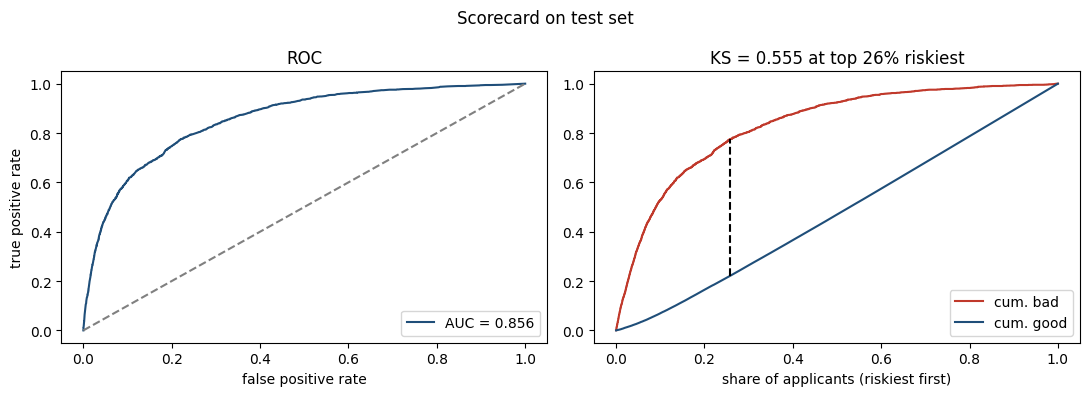

In [29]:
#把 KS 画出来
#KS 曲线的做法：
#把所有客户按风险从高到低排队（分数最低的排最前面）。
#从队头开始往后数，每数一个人，就统计：到目前为止，抓住了全部坏客户的百分之多少，误伤了全部好客户的百分之多少？
#画出两条累计曲线：红色是坏客户，蓝色是好客户。
#两条线之间的最大距离，就是 KS。
import matplotlib.pyplot as plt
plt.rcParams["axes.unicode_minus"] = False#axes.unicode_minus控制图表中的负号如何显示。设置为False，主要是避免中文字体环境下负号显示异常。

def plot_ks_roc(y, risk, title):#接受三个参数：违约结果，分数，标题
    fpr, tpr, _ = roc_curve(y, risk)#计算ROC曲线的数据，返回假正率，真正率，阈值
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))#一行二列；所以axes[0]表示左图，[1]表示右图

    # 左图：ROC 曲线
    axes[0].plot(fpr, tpr, color="#1f4e79", label=f"AUC = {roc_auc_score(y, risk):.3f}")#横轴fpr，纵轴tpr，标签是auc
    #AUC不是另外画出来的一条曲线，而是对ROC曲线整体表现进行总结的一个数字。AUC衡量的是模型整体的排序区分能力，而不是模型在某一个阈值下的准确率。
    axes[0].plot([0, 1], [0, 1], "--", color="grey")#画一条灰色虚线，设置两个端点，这个线代表没有区分能力的auc=0.5的线
    axes[0].set_xlabel("false positive rate")
    axes[0].set_ylabel("true positive rate")
    axes[0].set_title("ROC")
    axes[0].legend(loc="lower right")#loc="lower right"表示图例放在右下角

    # 右图：KS 曲线
    #核心：随着筛选人数增加，分别抓住了多少坏客户，又误伤了多少好客户？
    order = np.argsort(-np.asarray(risk))#risk转np数组，取负号，返回从高到低排序后的原始位置（排位置）
    y_sorted = np.asarray(y)[order]#按照风险排序重新排列真实标签（根据位置排标签即y值）
    cum_bad = np.cumsum(y_sorted) / y_sorted.sum()#累计求和/总求和。即不同位置下的tpr
    cum_good = np.cumsum(1 - y_sorted) / (1 - y_sorted).sum()#同理得到fpr
    pop = np.arange(1, len(y_sorted) + 1) / len(y_sorted)#当前以前筛选了多少人（比例）
    gap = cum_bad - cum_good
    k = np.argmax(gap)
    axes[1].plot(pop, cum_bad, label="cum. bad", color="#c0392b")
    axes[1].plot(pop, cum_good, label="cum. good", color="#1f4e79")
    axes[1].vlines(pop[k], cum_good[k], cum_bad[k], linestyles="--", color="black")#vlines()就是画垂直线
    axes[1].set_title(f"KS = {gap[k]:.3f} at top {pop[k]:.0%} riskiest")
    axes[1].set_xlabel("share of applicants (riskiest first)")
    axes[1].legend(loc="lower right")

    fig.suptitle(title)#设置整张图的大标题
    plt.tight_layout()#自动调整子图间距，防止文字重叠
    plt.show()

plot_ks_roc(y_test, -score_test, "Scorecard on test set")

In [30]:
#业务意义：如果把分数最低的 26% 客户全部拒掉，就能拦住约 77% 的坏客户，代价是误拒约 22% 的好客户。这是"最能把好坏分开"的那条分数线。
#但要注意：KS 最大点不等于实际的拒绝线。拒掉 26% 的申请，对消金公司来说太多了，会损失大量好客户和收入。实际的拒绝线要结合通过率目标、业务收益、坏账成本来定，通常拒绝率低得多。下一步的分数段表，就是专门用来定拒绝线的。


#PSI：模型稳不稳定
#模型上线后，来申请的客户会变。比如公司换了获客渠道，以前是白领多，现在是学生多。客群变了，模型可能就不准了。
#**PSI（群体稳定性指标）**就是用来监控这件事的：比较两批客户的分数分布是否一样。
#怎么算
#用训练集的分数，按十分位切成 10 段，每段 10% 的人。这是"预期分布"。（落在每个分数段的人数比例）
#用同样的切点，看另一批客户（比如测试集，或者上线后某个月的客户）落在每段的比例。这是"实际分布"。
#每段算一下差异，加起来：
#PSI = sum_{i} ({实际占比}_i - {预期占比}_i)* ln{实际占比}i\{预期占比}i
#PSI	判断
#< 0.1	稳定
#0.1–0.25	有变化，需要关注
#> 0.25	不稳定，要排查原因，可能需要重新建模
def psi(expected, actual, n_bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, n_bins + 1)))#np.linspace在0-1之间生成11个边界的等间距数值。np.quantile根据你提供的分位点，计算训练集评分的实际数值边界。np.unique() 的作用是去重。 
    edges[0], edges[-1] = -np.inf, np.inf#两端设置为无穷
    e = pd.cut(expected, edges).value_counts(normalize=True, sort=False)
    #pd.cut() 的作用是：根据刚刚计算出来的 edges，把每个客户的评分分配到对应的区间。
    #value_counts()它的作用是统计每个区间有多少人。
    #normalize=True代表不返回人数，而是返回占比
    #sort=False表示按照原来的分箱顺序排列，不按照人数多少重新排序。
    a = pd.cut(actual, edges).value_counts(normalize=True, sort=False)
    #计算验证集的分箱占比
    e, a = e.clip(lower=1e-6), a.clip(lower=1e-6)
    #所有小于 1e-6 的数，都替换成 1e-6=0.000001。避免出现ln0/0.1
    return float(((a - e) * np.log(a / e)).sum())#带入psi公式

print(f"PSI（训练集 vs 验证集）= {psi(score_train, score_valid):.4f}")
print(f"PSI（训练集 vs 测试集）= {psi(score_train, score_test):.4f}")

PSI（训练集 vs 验证集）= 0.0007
PSI（训练集 vs 测试集）= 0.0002


In [31]:
#面试高频题："模型上线后 PSI 突然变大，你怎么排查？"
#答，分三步：
#定位是哪些变量变了：对每个入模变量单独算 PSI（叫变量 PSI 或 CSI），找出分布变化最大的那几个。（因为总体psi是单个psi相加）
#找业务原因：是不是换了获客渠道、推出了新产品、调整了营销活动或准入政策？还是上游数据源出了问题，比如某个字段取数口径变了、缺失率突然上升？
#评估影响、决定动作：如果只是客群变了，但模型的 KS、坏账率预测仍然准确，可以继续用、加强监控；如果模型效果也下降了，就要考虑调整分数线或重新建模。
#注意：1.PSI只能告诉我们分布发生了变化，不能直接告诉我们模型预测能力下降了。
#2.要判断模型效果，必须等真实的还款结果（标签Y）产生，才能重新计算AUC、KS以及实际坏账率。
#3.所以实际风控监控会同时看：- 早期：PSI、客户结构、数据质量、审批通过率等。- 后期：等表现期成熟，再看AUC、KS、实际坏账率和预测校准情况。
#另外可以补一句：我的评分卡里，income、debt_ratio、monthly_debt 三个变量的缺失箱是同一批人。如果收入缺失率上升，三个变量会同时漂移，PSI 会被放大，这是我在模型里发现的一个风险点。

In [32]:
#分数段表（Lift 表）：定拒绝线的依据
#这是业务方最爱看的表。把测试集按分数从低到高切成 10 段，每段 10% 的人，看每一段的坏账率，以及从最低分开始累计拦住了多少坏客户。
def score_band_table(score, y, n=10):
    t = pd.DataFrame({"score": score, "y": y})
    t["band"] = pd.qcut(t["score"], q=n, duplicates="drop")
    #pd.qcut()：按照分位数，把数据分成指定数量的组，每组数量大致相同，去掉重复切点
    g = t.groupby("band", observed=True)["y"].agg(["count", "sum"])
    #按照band分组，统计人数和坏客户数
    g.columns = ["人数", "坏客户"]#改列名
    g["坏账率"] = g["坏客户"] / g["人数"]
    g["累计坏客户占比"] = g["坏客户"].cumsum() / g["坏客户"].sum()#从最高风险客户开始，逐步扩大覆盖范围，能够抓住多少坏客户。
    g["累计人数占比"] = g["人数"].cumsum() / g["人数"].sum()
    #举例：只看评分最低的10%客户，就能覆盖35%的坏客户。看评分最低的20%客户，就能覆盖60%的坏客户。
    g["Lift"] = g["坏账率"] / t["y"].mean()#某组坏账率/整体坏账率
    return g.round(4)

band = score_band_table(score_test, y_test)
band

,人数,坏客户,坏账率,累计坏客户占比,累计人数占比,Lift
band,,,,,,
"(319.843, 501.767]",3001,1060,0.3532,0.5287,0.1000,5.2850
"(501.767, 564.442]",3000,332,0.1107,0.6943,0.2000,1.6559
"(564.442, 596.084]",3006,221,0.0735,0.8045,0.3002,1.1000
"(596.084, 625.69]",2999,145,0.0483,0.8768,0.4002,0.7234
"(625.69, 652.293]",3035,97,0.0320,0.9252,0.5014,0.4782
"(652.293, 672.56]",2984,66,0.0221,0.9581,0.6008,0.3309
"(672.56, 688.31]",3262,35,0.0107,0.9756,0.7096,0.1605
"(688.31, 701.95]",2732,14,0.0051,0.9825,0.8006,0.0767
"(701.95, 716.011]",3062,21,0.0069,0.9930,0.9027,0.1026


In [33]:
#公司规定：拒绝率不能超过 15%。你会把分数线定在多少分？这时能拦住多少坏客户？
#1.算出测试集分数的 15% 分位数，这就是分数线。
#2.分数 ≤ 分数线的人，就是被拒的人。
#3.数一数被拒的人里有多少坏客户，除以全部坏客户。
cutoff = score_test.quantile(0.15)#quantile() 是分位数函数
reject = score_test < cutoff

print(f"分数线：{cutoff:.1f} 分")
print(f"拒绝率：{reject.mean():.2%}")
print(f"拦住的坏客户占比：{y_test[reject].sum() / y_test.sum():.2%}")#被拒绝的客户中，有多少个坏客户。除以总客户
print(f"被拒客户的坏账率：{y_test[reject].mean():.2%}")
print(f"通过客户的坏账率：{y_test[~reject].mean():.2%}")

分数线：545.3 分
拒绝率：14.99%
拦住的坏客户占比：63.49%
被拒客户的坏账率：28.31%
通过客户的坏账率：2.87%


In [34]:
#只拒 15% 的人，就挡掉了近三分之二的坏客户；被拒的人里，每 4 个就有 1 个多会违约，拒得有道理；通过客户的坏账率从 6.68% 降到 2.82%，降低了约 58%
#"按拒绝率不超过 15% 的要求，分数线定在 545 分，低于 545 分的申请拒绝。这样能拦住约 63.5% 的坏客户，通过客户的坏账率从 6.68% 降到 2.87%，降低了约 57%。"

In [35]:
#第 11 步：LightGBM / XGBoost 挑战者模型
#评分卡是主模型（冠军），但团队总会问：换一个更复杂的模型，效果能不能更好？用来和主模型比较的模型，就叫挑战者模型。
#在消金和互联网银行，常见的做法是"评分卡 + 机器学习模型"并行：评分卡负责可解释、稳定；树模型负责提升区分能力，可以做挑战者，也可以作为一个子分输入到评分卡或策略里。
#LightGBM 和 XGBoost 是什么
#两者都是梯度提升树（GBDT）：把几百棵小决策树串起来，每一棵树专门去修正前面所有树犯的错。它们是目前表格数据上效果最好的一类模型，原理差不多，只是实现细节不同。面试时知道"都是 GBDT 的高效实现"就够了。
#这两个模型直接使用清洗和特征工程后的原始变量，而不是 WOE 转换后的变量。所以导入的是train[X_cols]
#因为树模型能够直接学习变量与风险之间的非线性关系，不需要像逻辑回归那样依赖 WOE 转换。
import xgboost as xgb

X_cols = step3

lgb_model = lgb.LGBMClassifier(  #最多允许模型训练3000棵决策树；学习率0.02；每棵树最多允许有15个叶子节点；每个叶子节点至少要有200条训练样本；每棵树训练时，随机抽取80%的训练样本；
    n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=200,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,#它表示每训练1轮就进行一次随机抽样；那么每棵树只随机使用其中约80%的变量；
    random_state=SEED, verbose=-1,#正则化限制模型复杂度，减少过拟合；固定种子；闭嘴；
)
lgb_model.fit(train[X_cols], y_train, eval_set=[(valid[X_cols], y_valid)], eval_metric="auc",#拿训练集的特征和对应的真实标签进行学习；再加入验证集判断什么时候应该停止训练（看两个数据集的auc怎么变。如果训练集一直上升，但是测试机先升后降，可以判断出早停点）
              callbacks=[lgb.early_stopping(150, verbose=False)])#表示使用 验证集AUC 作为验证指标；如果连续150轮都没有超过之前的最佳AUC，就停止训练

xgb_model = xgb.XGBClassifier(  #每棵树最多允许向下生长4层；限制叶子里的 Hessian 权重总和20.
    n_estimators=3000, learning_rate=0.02, max_depth=4, min_child_weight=20,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    eval_metric="auc", early_stopping_rounds=150, random_state=SEED, n_jobs=4,#允许使用4个CPU线程进行并行计算。它主要影响训练速度，不是模型预测准确率的直接控制参数。
)
xgb_model.fit(train[X_cols], y_train, eval_set=[(valid[X_cols], y_valid)], verbose=False)

print("LightGBM 最优轮数：", lgb_model.best_iteration_)
print("XGBoost  最优轮数：", xgb_model.best_iteration)

LightGBM 最优轮数： 401
XGBoost  最优轮数： 505


In [36]:
#比较三个模型
p = {
    "评分卡（WOE+LR）": (-score_train, -score_test),#predict_proba 可以理解为 probability prediction，即概率预测；保留所有客户的第1列，也就是所有客户成为坏客户的预测概率
    "LightGBM": (lgb_model.predict_proba(train[X_cols])[:, 1], lgb_model.predict_proba(test[X_cols])[:, 1]),
    "XGBoost": (xgb_model.predict_proba(train[X_cols])[:, 1], xgb_model.predict_proba(test[X_cols])[:, 1]),
}
rows = []
for name, (ptr, pte) in p.items():
    rows.append({"模型": name,
                 "训练集AUC": roc_auc_score(y_train, ptr), "测试集AUC": roc_auc_score(y_test, pte),
                 "训练集KS": ks_stat(y_train, ptr), "测试集KS": ks_stat(y_test, pte)})
compare = pd.DataFrame(rows).set_index("模型").round(4)
compare["KS差距(训练-测试)"] = (compare["训练集KS"] - compare["测试集KS"]).round(4)
compare

,训练集AUC,测试集AUC,训练集KS,测试集KS,KS差距(训练-测试)
模型,,,,,
评分卡（WOE+LR）,0.8568,0.8558,0.5585,0.5548,0.0037
LightGBM,0.8789,0.8658,0.5993,0.5750,0.0243
XGBoost,0.8762,0.8657,0.5943,0.5735,0.0208


In [37]:
#1 个点的 AUC，到底值多少？
#L比评分卡的auc高一个百分点，在同样 15% 的拒绝率下，两个模型各能拦住多少坏客户？
def catch_at_reject_rate(risk, y, rate=0.15):
    risk = np.asarray(risk)#把list数据转化为np数组
    cutoff = np.quantile(risk, 1 - rate)#就是计算风险值的第85百分位数，使得大约85%的客户风险值在这个点以下
    reject = risk > cutoff
    return reject.mean(), y[reject].sum() / y.sum(), y[~reject].mean()#返回实际拒绝率，实际拒绝/总坏数，通过客户的坏账率

for name, (_, pte) in p.items():#pte是测试机的风险预测
    r, caught, pass_bad = catch_at_reject_rate(pte, y_test.values)#.values 将series转换为 NumPy 数组，方便后续使用布尔数组进行筛选。
    print(f"{name:14s} 拒绝率 {r:.2%}  拦住坏客户 {caught:.2%}  通过客户坏账率 {pass_bad:.2%}")#把模型名称按至少14个字符的宽度显示，方便对齐

评分卡（WOE+LR）    拒绝率 14.99%  拦住坏客户 63.49%  通过客户坏账率 2.87%
LightGBM       拒绝率 15.00%  拦住坏客户 65.69%  通过客户坏账率 2.70%
XGBoost        拒绝率 15.00%  拦住坏客户 65.94%  通过客户坏账率 2.68%


In [38]:
#练习 7：亲眼看看过拟合
#把 LightGBM 调得更复杂，看看会发生什么。
lgb_big = lgb.LGBMClassifier(
    n_estimators=3000, learning_rate=0.02, num_leaves=63, min_child_samples=20,#分支变大63，每只叶子只要20人
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=SEED, verbose=-1,
)
lgb_big.fit(train[X_cols], y_train, eval_set=[(valid[X_cols], y_valid)], eval_metric="auc",
            callbacks=[lgb.early_stopping(150, verbose=False)])

ptr = lgb_big.predict_proba(train[X_cols])[:, 1]
pte = lgb_big.predict_proba(test[X_cols])[:, 1]
print("最优轮数：", lgb_big.best_iteration_)
print(f"训练集 KS {ks_stat(y_train, ptr):.4f}  测试集 KS {ks_stat(y_test, pte):.4f}  差距 {ks_stat(y_train, ptr) - ks_stat(y_test, pte):.4f}")

最优轮数： 248
训练集 KS 0.6489  测试集 KS 0.5754  差距 0.0735


In [39]:
#模型变复杂后，训练集效果大涨，测试集效果却一点没涨。多出来的 5 个百分点，全是模型死记硬背训练集里的噪声和个别人的特征，换一批客户就不管用了。
#"怎么防止树模型过拟合？"
#答：限制复杂度（减少叶子数或树深、增大叶子最小样本数）、加随机性（行列采样 subsample、colsample）、加正则（reg_lambda）、
#用验证集早停。判断标准是看训练集和验证集、测试集的指标差距。

In [40]:
%pip install toad


   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
   - ---------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
import toad
print(toad.__version__)

%who DataFrame##列出当前 Notebook 里所有的表格变量名。我需要知道你的训练集叫什么名字，下一步要用

0.1.7
band	 c	 compare	 corr	 d	 df	 df_clean	 df_feat	 eda	 
iv_df	 raw	 res	 scorecard	 t	 tab	 temp	 test	 train	 
valid	 woe_test	 woe_train	 woe_valid	 


In [42]:
print(train.shape)#先看清楚两张表长什么样
print(train.columns.tolist())
iv_df.head(25)

(90000, 21)
['y', 'util', 'age', 'dpd30', 'debt_ratio', 'income', 'open_lines', 'dpd90', 're_loans', 'dpd60', 'dependents', 'dpd_special', 'income_missing', 'dpd_total', 'dpd_any', 'dpd_severity', 'monthly_debt', 'income_per_person', 'lines_per_age', 're_share', 'util_high']


,IV,区分能力
dpd_severity,1.4010,极强
dpd_total,1.3514,极强
dpd_any,1.1737,极强
util,1.0973,极强
dpd90,0.8502,极强
dpd30,0.7147,极强
util_high,0.6108,极强
age,0.2285,中
income_per_person,0.1018,中
income,0.0804,弱


In [43]:
#再用 toad 算 IV
q = toad.quality(
    train,
    target='y',
    indicators=['iv'],
    cpu_cores=1,
    n_bins=6,
    min_samples=0.05,#和你手写版的设置一样：决策树分箱，最多 6 箱，每箱至少 5% 的样本。设置一致，对比才公平
)
q

,iv
dpd_severity,1.333251
dpd_total,1.283636
dpd_any,1.138510
util,1.097532
dpd90,0.803212
dpd30,0.663259
util_high,0.610823
dpd60,0.561643
age,0.228557
income_per_person,0.117726


In [44]:
#结果解读：util、age、util_high、income_missing 几乎完全一样。这几个变量没有缺失值，分箱后本来就单调，两边方法等价，结果就该一样。
#第 2 类：逾期变量 toad 偏低 → 缺失值的处理方式不同
  #dpd30、dpd90、dpd_severity 都有缺失值，就是 96/98 置空的那 269 人，坏账率 54.6%。
  #原因推测：之前手写版：缺失值单独一箱（Missing 箱），这批高风险客户被单独识别出来；
  #toad 默认：把缺失值填成 −1，再和其他值一起用决策树切。这批人只占 0.2%，达不到每箱 5% 的要求，切不出独立的箱，被并进了「0 次逾期」那一箱。高风险信息被冲淡，IV 就低了
#第 3 类：re_loans、re_share 高了 8 到 9 倍 → 强制单调的代价——这两个变量在你的手写版里 IV 不到 0.02，在第 7 步第一道筛子就被剔除了。但 toad 算出来有约 0.06。
  #最可能的原因和 open_lines 一样：U 型关系。房贷数量为 0 的人（没有房产）和房贷特别多的人（杠杆高），风险都偏高，中间的人最安全。强制单调把 U 型压平了，IV 跟着塌掉，变量直接被筛掉。
#强制单调：评分卡好解释（「房贷越多分越低」），但丢信息
#不强制单调：保留信息，但要向业务方解释「为什么 0 套和 5 套都扣分」
#第 4 类：dpd60、dpd_special 高很多 → 要警惕「虚高」
  #toad 有一条规则：取值不超过 10 种的变量，会被当成类别变量，每个取值直接作为一箱，不合并、也不管每箱 5% 的限制。
  #dpd60 只有十来个取值，dpd_special 只有 0 和 1，都被这样处理了。于是出现了很多人数很少的箱。
  #小箱子会让 IV 虚高：一个箱只有 30 个人，偶然多了几个坏客户，WOE 就会很极端，IV 跟着变大。


#第 3 步：用实验验证第 2 类和第 4 类的推测
#toad 的 Combiner 可以控制分箱细节，并且导出切点。我们让它和你的手写版尽量一致：
c = toad.transform.Combiner()
c.fit(
    train,
    y='y',
    method='dt',#这是最核心的参数！决策树分箱（Decision Tree）。大白话：机器会像之前学的决策树一样，自动去找那些“能把好人坏人最大程度区分开”的切割点
    n_bins=6,
    min_samples=0.05,
    empty_separate=True,#把“空值（缺失值）”单独踢出来当一个独立的箱子。
)

for col in ['dpd30', 'dpd60', 're_loans']:
    print(col, c.export()[col])#机器切完蛋糕后，你把它的“分箱记录本”拿出来。从记录本里，专门翻出这三个变量对应的分箱规则。即：导出每个变量的切点



dpd30 [0.5, 1.5, nan]
dpd60 [nan]
re_loans [0.5, 1.5, 2.5]


In [45]:
#然后用切点重新算 IV：
train_bin = c.transform(train)
for col in ['dpd30', 'dpd90', 'dpd_severity', 'dpd60', 're_loans']:
    print(col, round(toad.stats.IV(train_bin[col], train['y']), 4))#toad.stats.IV计算IV

dpd30 0.7147
dpd90 0.8502
dpd_severity 1.4011
dpd60 0.0359
re_loans 0.0579


In [ ]:
#结果分析：加上 empty_separate=True 后，和手写版完全一致。差异的原因确认是缺失值有没有单独成箱。
#dp60分箱原因：「每箱至少 5%」这个限制。 dpd60 > 0 的人不到 5%，决策树没法把「0 次」和「1 次及以上」切开，dpd60 的风险信息几乎全丢了。

In [ ]:
#下一步：整理 GitHub 仓库
#面试官看到简历上的项目，经常会问「有代码吗？」。能直接给一个链接，展示清晰的代码 + 说明文档，比口头描述有说服力得多。
